Level 1 Internship Tasks   
Task 1: Data Cleaning and Preprocessing
Task 2: Exploratory Data Analysis (EDA)
Dataset Used: Churn Prediction Dataset

Tools:

Python
Pandas
Matplotlib
Seaborn


In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Importing Required Libraries
The following libraries were imported for data analysis and visualization:

Pandas for data manipulation and preprocessing.
Matplotlib for creating visualizations.
Seaborn for statistical data visualization.

In [65]:
train_df = pd.read_csv("churn-bigml-80.csv")
test_df = pd.read_csv("churn-bigml-20.csv")

print("80% Dataset Shape:", train_df.shape)
print("20% Dataset Shape:", test_df.shape)

80% Dataset Shape: (2666, 20)
20% Dataset Shape: (667, 20)


Both churn datasets were loaded successfully using pandas.
Observations
The training dataset () contains 2,666 rows and 20 columns.
The testing dataset () contains 667 rows and 20 columns.
Both datasets have the same number of features, making them suitable for further analysis and predictive modeling.

In [66]:
train_df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


The first five rows of the churn dataset were displayed using the head() function. This provides an initial overview of the dataset structure, available features, and target variable.

A total of 20 columns are available for analysis.
The dataset includes numerical and categorical variables.
The data appears suitable for further cleaning and exploratory analysis.

In [67]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   float64
 15

The dataset contains 2,666 records and 20 columns. All columns have complete data with no missing values. The features include numerical, categorical, and boolean variables, making the dataset suitable for customer churn analysis.

In [68]:
train_df.isnull().sum()

State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64

The dataset contains 2,666 records and 20 columns. It includes numerical, categorical, and boolean variables. No missing values were found, and the target variable is churn which indicates whether a customer left the service provider.​‌


In [69]:
train_df.isnull().sum().sum()

np.int64(0)

The total number of missing values in the dataset is 0. No data imputation or row removal was required.The dataset is considered complete and suitable for further analysis.

In [70]:
train_df.duplicated().sum()

np.int64(0)

No duplicate records were found in the dataset 

In [71]:
train_df = train_df.drop_duplicates()

print("Duplicate records removed successfully")

Duplicate records removed successfully


In [72]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   float64
 15

In [73]:
cat_cols = train_df.select_dtypes(include='object').columns

for col in cat_cols:
    if col != "State":
        train_df[col] = train_df[col].str.strip().str.title()

C:\Users\HP\AppData\Local\Temp\ipykernel_2032\1581664826.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train_df.select_dtypes(include='object').columns


In [74]:
cat_cols = train_df.select_dtypes(include=['object', 'string']).columns

In [75]:
cat_cols = train_df.select_dtypes(include=['object', 'string']).columns

In [76]:
print(train_df["International plan"].unique())
print(train_df["Voice mail plan"].unique())
print(train_df["Churn"].unique())

<StringArray>
['No', 'Yes']
Length: 2, dtype: str
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
[False  True]


In [77]:
print(train_df["State"].unique())

<StringArray>
['KS', 'OH', 'NJ', 'OK', 'AL', 'MA', 'MO', 'WV', 'RI', 'IA', 'MT', 'ID', 'VT',
 'VA', 'TX', 'FL', 'CO', 'AZ', 'NE', 'WY', 'IL', 'NH', 'LA', 'GA', 'AK', 'MD',
 'AR', 'WI', 'OR', 'DE', 'IN', 'UT', 'CA', 'SD', 'NC', 'WA', 'MN', 'NM', 'NV',
 'DC', 'NY', 'KY', 'ME', 'MS', 'MI', 'SC', 'TN', 'PA', 'HI', 'ND', 'CT']
Length: 51, dtype: str


Categorical variables were standardized to ensure consistency. All categorical columns except State were cleaned by removing extra spaces and converting values to title case (e.g., "yes", "YES" → "Yes"). The State column was left unchanged to preserve state abbreviations such as "IN" and "OH".

In [78]:
train_df.to_csv("churn_cleaned.csv", index=False)

print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully


Task 2: Exploratory Data Analysis (EDA)
Objective
The objective of this task is to analyze the churn dataset, generate summary statistics, identify patterns and relationships, and visualize key insights using charts and graphs.

In [79]:
train_df.describe()

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
count,2666.000000,2666.000000,2666.000000,2666.00000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000
mean,100.620405,437.438860,8.021755,179.48162,100.310203,30.512404,200.386159,100.023631,17.033072,201.168942,100.106152,9.052689,10.237022,4.467367,2.764490,1.562641
std,39.563974,42.521018,13.612277,54.21035,19.988162,9.215733,50.951515,20.161445,4.330864,50.780323,19.418459,2.285120,2.788349,2.456195,0.752812,1.311236
min,1.000000,408.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,43.700000,33.000000,1.970000,0.000000,0.000000,0.000000,0.000000
25%,73.000000,408.000000,0.000000,143.40000,87.000000,24.380000,165.300000,87.000000,14.050000,166.925000,87.000000,7.512500,8.500000,3.000000,2.300000,1.000000
50%,100.000000,415.000000,0.000000,179.95000,101.000000,30.590000,200.900000,100.000000,17.080000,201.150000,100.000000,9.050000,10.200000,4.000000,2.750000,1.000000
75%,127.000000,510.000000,19.000000,215.90000,114.000000,36.700000,235.100000,114.000000,19.980000,236.475000,113.000000,10.640000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,50.000000,350.80000,160.000000,59.640000,363.700000,170.000000,30.910000,395.000000,166.000000,17.770000,20.000000,20.000000,5.400000,9.000000


Descriptive statistics were generated to understand the distribution of numerical variables in the dataset.

The statistics include:

Mean
Standard Deviation
Minimum Value
Maximum Value
Quartiles (25%, 50%, and 75%)
These measures provide insight into the central tendency and variability of the dataset.

In [80]:
train_df.mean(numeric_only=True)

Account length            100.620405
Area code                 437.438860
Number vmail messages       8.021755
Total day minutes         179.481620
Total day calls           100.310203
Total day charge           30.512404
Total eve minutes         200.386159
Total eve calls           100.023631
Total eve charge           17.033072
Total night minutes       201.168942
Total night calls         100.106152
Total night charge          9.052689
Total intl minutes         10.237022
Total intl calls            4.467367
Total intl charge           2.764490
Customer service calls      1.562641
Churn                       0.145536
dtype: float64

The mean values of all numerical features were calculated using the mean() function.

Observation
The Churn variable is stored as a boolean data type. During mean calculation, pandas interprets:

False = 0
True = 1
As a result, the mean of the Churn column represents the proportion of customers who churned.

This provides insight into the overall churn rate within the dataset.

In [1]:
train_df.median(numeric_only=True)

NameError: name 'train_df' is not defined

In [2]:
import pandas as pd

train_df = pd.read_csv("churn-bigml-80.csv")
test_df = pd.read_csv("churn-bigml-20.csv")

In [3]:
train_df.median(numeric_only=True)

Account length            100.00
Area code                 415.00
Number vmail messages       0.00
Total day minutes         179.95
Total day calls           101.00
Total day charge           30.59
Total eve minutes         200.90
Total eve calls           100.00
Total eve charge           17.08
Total night minutes       201.15
Total night calls         100.00
Total night charge          9.05
Total intl minutes         10.20
Total intl calls            4.00
Total intl charge           2.75
Customer service calls      1.00
Churn                       0.00
dtype: float64

Median Analysis
The median was calculated to identify the middle value of each numerical feature.

In [4]:
train_df.mode()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,WV,93.0,415.0,No,No,0.0,162.3,105.0,27.59,169.9,105.0,14.25,214.7,105.0,9.66,10.0,3.0,2.7,1.0,False
1,NaN,NaN,NaN,NaN,NaN,NaN,183.4,NaN,31.18,NaN,NaN,16.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Mode Analysis
The mode identifies the most frequently occurring value in each column.

This helps highlight common patterns within the dataset.

In [5]:
train_df.std(numeric_only=True)

Account length            39.563974
Area code                 42.521018
Number vmail messages     13.612277
Total day minutes         54.210350
Total day calls           19.988162
Total day charge           9.215733
Total eve minutes         50.951515
Total eve calls           20.161445
Total eve charge           4.330864
Total night minutes       50.780323
Total night calls         19.418459
Total night charge         2.285120
Total intl minutes         2.788349
Total intl calls           2.456195
Total intl charge          0.752812
Customer service calls     1.311236
Churn                      0.352707
dtype: float64

Standard Deviation Analysis
The standard deviation was calculated to measure the variability of numerical features.

Higher standard deviation values indicate greater dispersion from the mean.

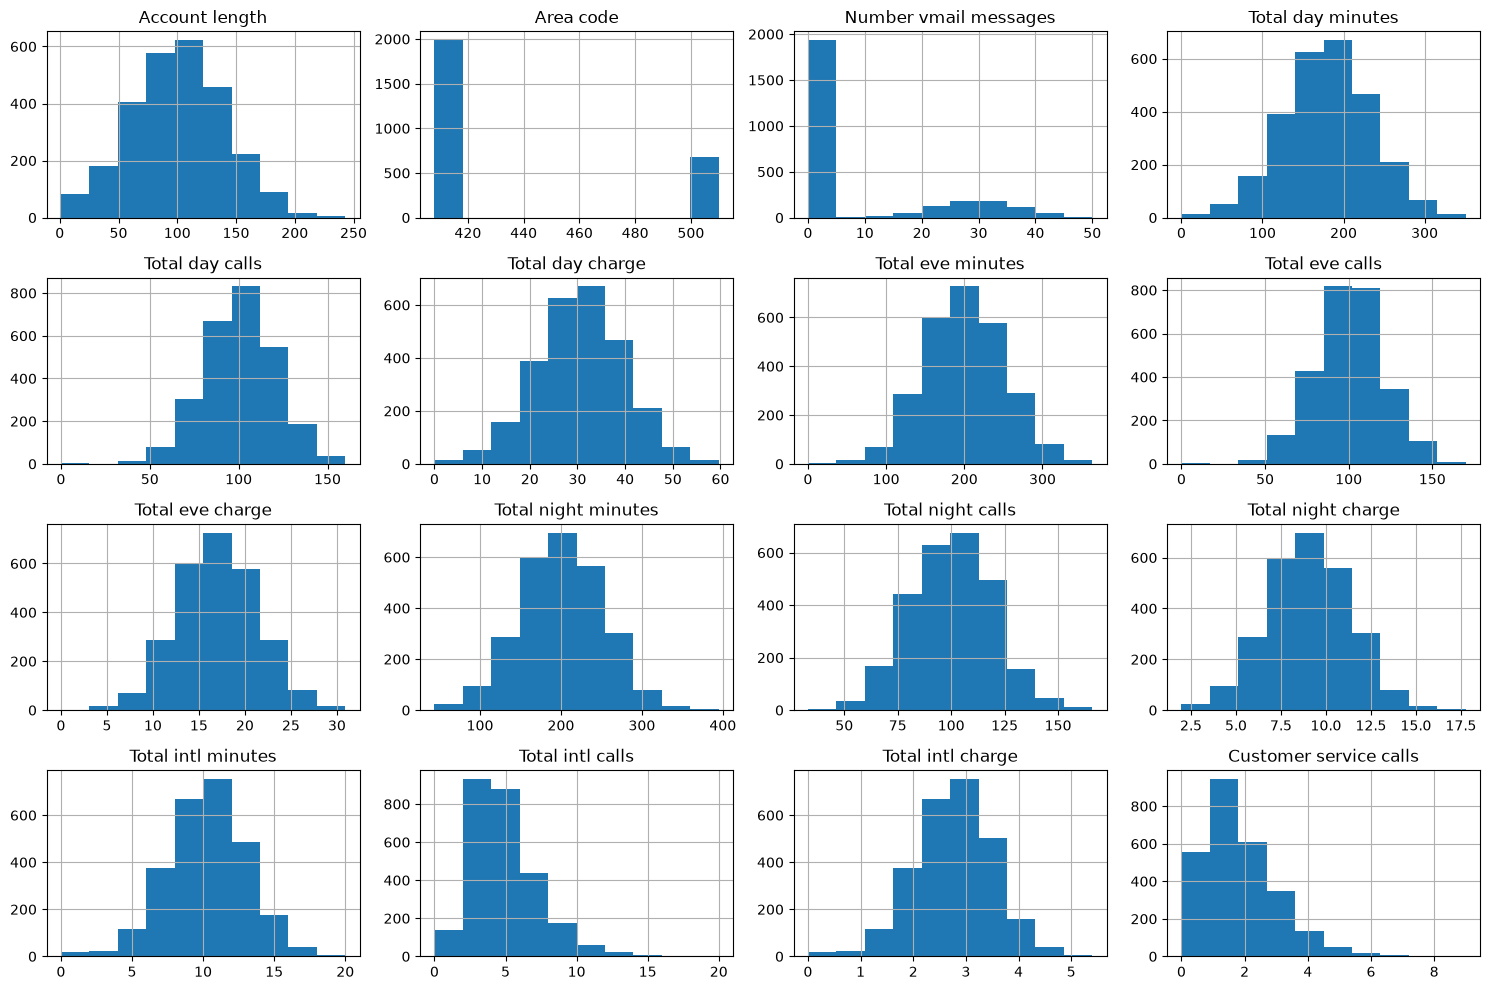

In [7]:
import matplotlib.pyplot as plt

train_df.hist(figsize=(15,10))

plt.tight_layout()
plt.show()

Histogram Analysis
The histograms were created to understand how the values in each numerical column are distributed.

Observations
Most customer account lengths fall between 50 and 150.
The area code column contains only a few specific values, which is why there are only a few bars.
Most customers have few or no voicemail messages.
Day, evening, and night call durations are mostly concentrated around the middle values, with fewer customers having extremely high or low usage.
Most customers make around 80 to 120 calls during the day, evening, and night periods.
International calls are generally low for most customers.
Most customers contact customer service between 1 and 3 times.
Conclusion
The histograms show that most features have a reasonable distribution with no major issues. They also help identify customer usage patterns and provide a better understanding of the dataset before building predictive models.

In [8]:
plt.figure(figsize=(12,6))

sns.boxplot(data=train_df.select_dtypes(include=['int64','float64']))

plt.xticks(rotation=90)
plt.title("Boxplot of Numerical Features")
plt.show()

NameError: name 'sns' is not defined

<Figure size 1200x600 with 0 Axes>

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

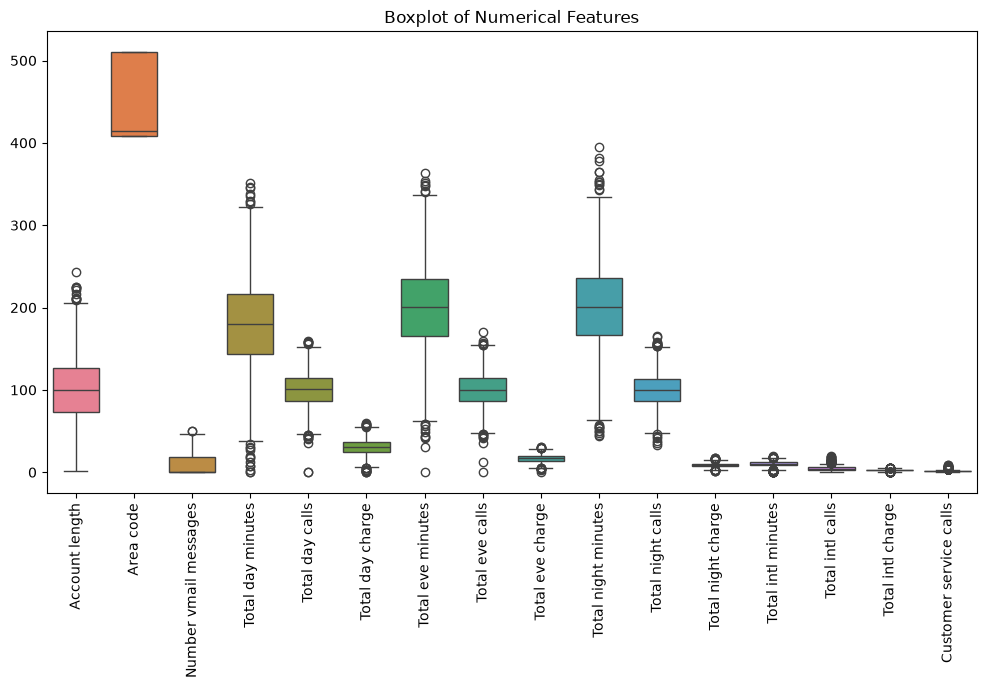

In [10]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=train_df.select_dtypes(include=['int64','float64'])
)

plt.xticks(rotation=90)
plt.title("Boxplot of Numerical Features")
plt.show()

Boxplots were generated to examine the distribution of numerical features and identify potential outliers.

Most features are centered around their median values.
Several variables contain outliers, indicating unusual customer behavior.
Total Day Minutes, Total Evening Minutes, and Total Night Minutes show greater variability in customer usage.
Total International Calls and Customer Service Calls contain noticeable outliers.
The boxplots revealed variations in customer behavior and highlighted outliers that may be important for understanding churn patterns and future predictive modeling.

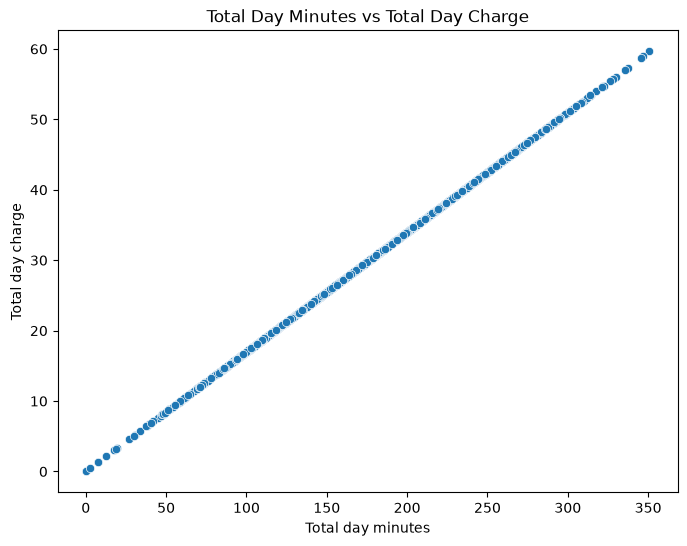

In [11]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x='Total day minutes',
    y='Total day charge',
    data=train_df
)

plt.title("Total Day Minutes vs Total Day Charge")
plt.show()

Scatter Plot Analysis
A scatter plot was created to examine the relationship between Total Day Minutes and Total Day Charge.

A strong positive linear relationship exists between the two variables.
As total day minutes increase, total day charges also increase.
The data points form an almost perfect straight line, indicating a very high correlation.

The scatter plot shows that day charges are directly related to day-time usage. Customers who use more daytime minutes incur higher charges, making these variables strongly correlated.

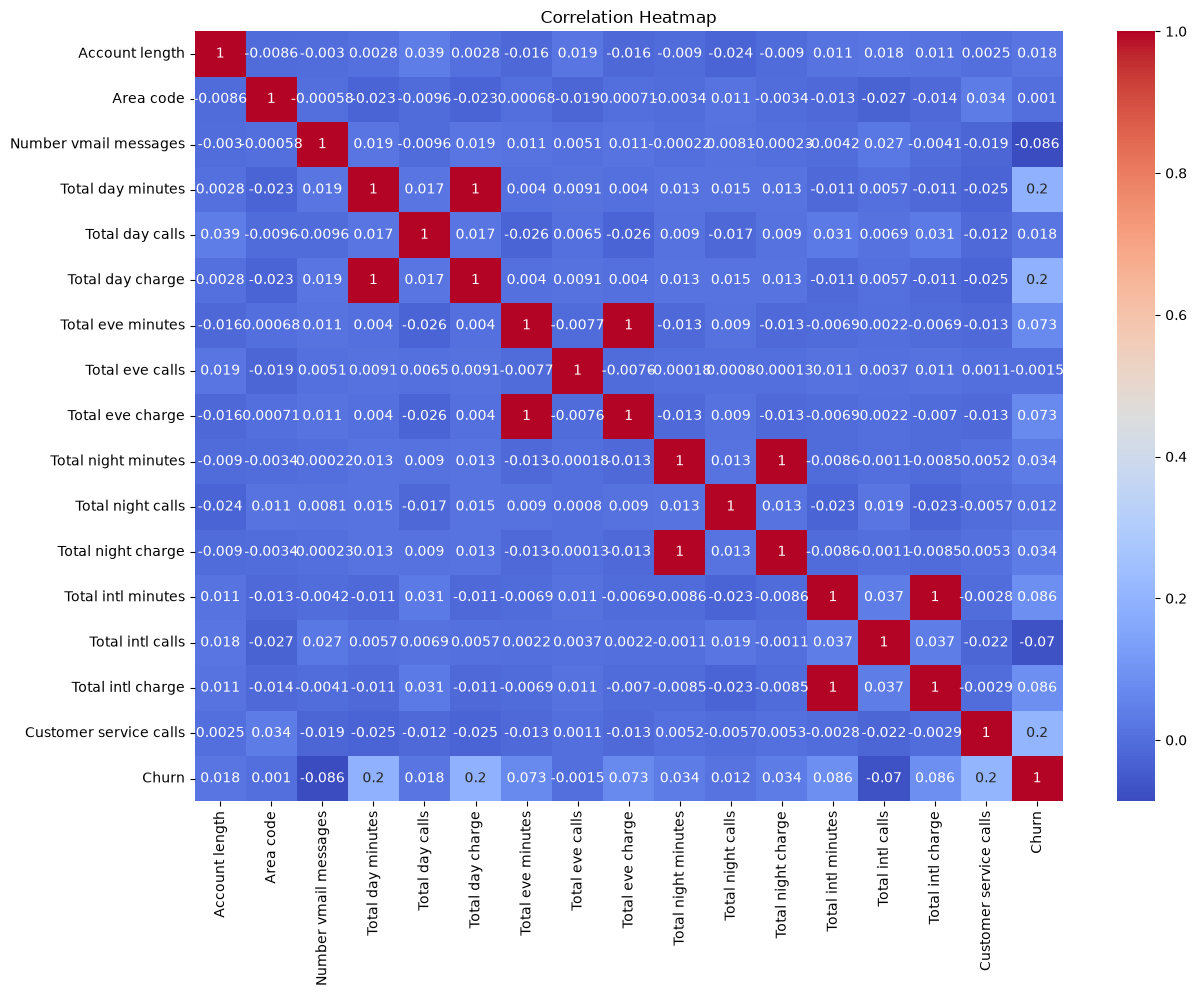

In [12]:
plt.figure(figsize=(14,10))
 
sns.heatmap(
train_df.corr(numeric_only=True),
annot=True,
cmap='coolwarm'
)
 
plt.title("Correlation Heatmap")
plt.show()


The correlation analysis showed strong positive relationships between service usage and their corresponding charges, as charges are directly calculated from customer usage. The strongest correlations with customer churn were observed for Total Day Minutes, Total Day Charge, and Customer Service Calls. Overall, the heatmap provided valuable insights into customer behavior and highlighted key variables that may influence churn, making them useful for future predictive modeling.

Conclusion
The churn dataset was successfully cleaned and analyzed.

The analysis included:

Summary statistics
Histograms
Boxplots
Scatter plots
Correlation analysis
The results provided insights into customer behavior and prepared the dataset for future predictive modeling tasks.